# Etapa 5 — Redes Bayesianas: DAG, CPTs, inferência por enumeração e d-separação

**Pergunta prática (a mesma das Etapas 1 e 4):** dado o perfil e os sintomas de um paciente com dengue notificado, ele será hospitalizado?

**Dados:** Sinan/Dengue 2026 (`DENGBR26.csv`), Portal de Dados Abertos do SUS.

**Atributos:** os mesmos da Etapa 1, com o mesmo balanceamento 50/50 e a mesma divisão treino/teste (seed 42), reconstruídos por `treino_teste_etapa1` do `utils1e2.py` (arquivo do repositório, **não alterado**). O enunciado pede uma rede de 4 a 6 nós, então a rede usa a hospitalização e 5 dos 6 atributos (a escolha está justificada na seção 3).

Antes de rodar, envie para `/content` os arquivos `DENGBR26.csv` e `utils1e2.py`. Se existir, envie também `etapa4_probabilidades_teste.csv` (saída da Etapa 4), que é usado na comparação da seção 9. Depois, rode as células em ordem (Ambiente de execução → Executar tudo).

In [ ]:
# No Colab, o pgmpy não vem instalado
!pip install -q pgmpy

In [ ]:
import warnings
warnings.filterwarnings("ignore")      # avisos de versão do pgmpy/tqdm
import os
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, log_loss

from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
try:                                    # pgmpy >= 1.0
    from pgmpy.models import DiscreteBayesianNetwork as RedePgmpy
except ImportError:                     # versões antigas
    from pgmpy.models import BayesianNetwork as RedePgmpy

# Do repositório: o mesmo arquivo usado nas Etapas 1 e 2 (sem alterações)
from utils1e2 import treino_teste_etapa1, ATRIBUTOS, faixa_etaria, regiao

SEED = 42
np.random.seed(SEED)
CAMINHO_CSV = "/content/DENGBR26.csv"
ALPHA = 1.0   # Laplace = MAP com prior Dirichlet(2), como na Etapa 4

print("atributos da Etapa 1:", ATRIBUTOS)

atributos da Etapa 1: ['regiao', 'LEUCOPENIA', 'faixa_etaria', 'VOMITO', 'CEFALEIA', 'HIPERTENSA']


## 1. Funções (tudo do zero)

As funções estão separadas por assunto. Uma rede é guardada como um dicionário com quatro partes:

* `pais[X]`: lista dos pais de X;
* `valores[X]`: valores possíveis de X;
* `ordem`: os nós em ordem topológica (pais antes dos filhos);
* `cpt[X]`: um array com um eixo para cada pai e o último eixo para X, isto é, `cpt[X][i_pai1, i_pai2, ..., i_x]` = $P(X = x \mid \text{pais})$.

O `pgmpy` é usado só para conferência (seções 6 e 7).

### 1.1 Preparação dos dados para a rede

Para as consultas ficarem legíveis, os sintomas passam de `1.0`/`2.0` para `sim`/`nao`, e o alvo (0/1) vira o nó `HOSP` com valores `nao`/`sim`. Os dados são os mesmos; só muda o rótulo.

In [ ]:
SIM_NAO = {"1.0": "sim", "2.0": "nao"}


def preparar_rede_df(df):
    """Cópia do DataFrame com rótulos legíveis para a rede."""
    d = df[ATRIBUTOS].copy()
    for a in ["LEUCOPENIA", "VOMITO", "CEFALEIA", "HIPERTENSA"]:
        d[a] = d[a].map(SIM_NAO).fillna(d[a])
    d["HOSP"] = df["alvo"].map({0: "nao", 1: "sim"})
    return d

### 1.2 Estrutura e CPTs (estimativa MAP com Laplace)

Cada linha da CPT é uma distribuição de X para uma combinação de valores dos pais (um *conditioning case*, AIMA 13.1). Ela é estimada por contagem com a mesma suavização da Etapa 4:

$$P(X = x \mid \text{pais} = u) = \frac{\text{cont}(x, u) + \alpha}{\text{cont}(u) + \alpha\,|X|}.$$

Com $\alpha = 1$ é a estimativa MAP com prior Dirichlet(2), e nenhuma combinação recebe probabilidade zero.

In [ ]:
def ordem_topologica(pais):
    """Ordena os nós de modo que todo pai venha antes do filho."""
    ordem, restantes = [], set(pais)
    while restantes:
        prontos = sorted(n for n in restantes if all(p in ordem for p in pais[n]))
        if not prontos:
            raise ValueError("o grafo tem ciclo")
        ordem += prontos
        restantes -= set(prontos)
    return ordem


def montar_rede(df, pais, valores, alpha=ALPHA):
    """Estima todas as CPTs a partir do DataFrame (contagem + Laplace)."""
    rede = {"pais": pais, "valores": valores, "ordem": ordem_topologica(pais), "cpt": {}}
    for X, ps in pais.items():
        forma = [len(valores[p]) for p in ps] + [len(valores[X])]
        cont = np.zeros(forma)
        # índice de cada coluna (pais ... X) em cada linha do DataFrame
        idx = [df[c].map({v: i for i, v in enumerate(valores[c])}).to_numpy() for c in ps + [X]]
        np.add.at(cont, tuple(idx), 1)
        rede["cpt"][X] = (cont + alpha) / (cont.sum(axis=-1, keepdims=True) + alpha * len(valores[X]))
    return rede


def tabela_cpt(rede, X):
    """CPT de X como DataFrame (uma linha por combinação dos pais)."""
    ps, cpt = rede["pais"][X], rede["cpt"][X]
    linhas = []
    for combo in itertools.product(*[range(len(rede["valores"][p])) for p in ps]):
        linha = {p: rede["valores"][p][i] for p, i in zip(ps, combo)}
        for k, v in enumerate(rede["valores"][X]):
            linha[f"P({X}={v})"] = cpt[combo + (k,)]
        linhas.append(linha)
    return pd.DataFrame(linhas)

### 1.3 Probabilidade conjunta e inferência por enumeração

* **Semântica da rede (AIMA, eq. 13.2):** $P(x_1,\dots,x_n) = \prod_i P(x_i \mid \text{pais}(X_i))$.
* **ENUMERATION-ASK (AIMA, fig. 13.11):** para uma consulta $P(X \mid e)$, soma a conjunta sobre todas as variáveis ocultas $y$ e normaliza: $P(X \mid e) = \alpha \sum_y P(X, e, y)$. A função `enumerar_tudo` percorre os nós em ordem topológica: se o nó tem valor (evidência ou consulta), multiplica pela sua probabilidade; senão, soma sobre os seus valores.

Este algoritmo é exponencial no número de variáveis ocultas, mas com 6 nós isso não é problema.

In [ ]:
def prob_no(rede, X, x, atrib):
    """P(X = x | pais(X)), com os valores dos pais lidos de 'atrib'."""
    v = rede["valores"]
    idx = tuple(v[p].index(atrib[p]) for p in rede["pais"][X]) + (v[X].index(x),)
    return rede["cpt"][X][idx]


def prob_conjunta(rede, atrib):
    """Eq. 13.2: produto das CPTs para uma atribuição completa."""
    return np.prod([prob_no(rede, X, atrib[X], atrib) for X in rede["ordem"]])


def enumerar_tudo(rede, variaveis, e):
    """ENUMERATE-ALL da AIMA: soma da conjunta sobre as variáveis que não estão em e."""
    if not variaveis:
        return 1.0
    Y, resto = variaveis[0], variaveis[1:]
    if Y in e:
        return prob_no(rede, Y, e[Y], e) * enumerar_tudo(rede, resto, e)
    return sum(prob_no(rede, Y, y, e) * enumerar_tudo(rede, resto, {**e, Y: y})
               for y in rede["valores"][Y])


def enumeration_ask(rede, X, e):
    """Distribuição P(X | e) por enumeração, como dicionário {valor: probabilidade}."""
    q = np.array([enumerar_tudo(rede, rede["ordem"], {**e, X: x}) for x in rede["valores"][X]])
    return {x: float(p) for x, p in zip(rede["valores"][X], q / q.sum())}

### 1.4 d-separação (do zero)

Procedimento da AIMA (seção 13.2.1) para saber se $X$ e $Y$ são condicionalmente independentes dado um conjunto $Z$:

1. ficar só com o **subgrafo ancestral** de $X \cup Y \cup Z$;
2. **moralizar**: ligar os pais que têm um filho em comum;
3. tirar a direção das arestas;
4. apagar os nós de $Z$. Se ainda existir caminho entre $X$ e $Y$, eles **não** são d-separados.

O passo 2 é o que trata o colisor: dois pais de um mesmo filho só ficam ligados se o filho (ou um descendente dele) está no subgrafo ancestral, isto é, se ele foi observado.

In [ ]:
def ancestrais(pais, nos):
    """Os nós dados mais todos os seus ancestrais."""
    resultado, pilha = set(nos), list(nos)
    while pilha:
        for p in pais[pilha.pop()]:
            if p not in resultado:
                resultado.add(p)
                pilha.append(p)
    return resultado


def d_separados(pais, X, Y, Z=()):
    """True se Z d-separa X de Y (X, Y: nomes de nós; Z: lista de nós observados)."""
    sub = ancestrais(pais, [X, Y, *Z])
    viz = {n: set() for n in sub}
    for n in sub:
        ps = [p for p in pais[n] if p in sub]
        for p in ps:                                   # arestas, agora sem direção
            viz[n].add(p); viz[p].add(n)
        for a, b in itertools.combinations(ps, 2):     # moralização: "casa" os pais
            viz[a].add(b); viz[b].add(a)
    # busca em largura sem passar pelos nós observados
    vistos, fila = {X}, [X]
    while fila:
        n = fila.pop()
        for m in viz[n] - set(Z):
            if m == Y:
                return False
            if m not in vistos:
                vistos.add(m)
                fila.append(m)
    return True

### 1.5 Contagem de parâmetros

Um nó $X$ precisa de $(|X| - 1) \times \prod_{P \in \text{pais}(X)} |P|$ números independentes (cada linha da CPT soma 1, então o último valor é dispensável). A distribuição conjunta completa precisa de $\prod_X |X| - 1$.

In [ ]:
def parametros(rede):
    """Números independentes por nó, total da rede e total da conjunta completa."""
    v = rede["valores"]
    por_no = {X: (len(v[X]) - 1) * int(np.prod([len(v[p]) for p in rede["pais"][X]]))
              for X in rede["ordem"]}
    conjunta = int(np.prod([len(v[X]) for X in rede["ordem"]])) - 1
    return por_no, sum(por_no.values()), conjunta

### 1.6 Avaliação como classificador

`prob_hosp_rede` calcula $P(\text{HOSP} = \text{sim} \mid \text{atributos do paciente})$ por enumeração. Como os pacientes repetem muito as mesmas combinações de atributos, cada combinação diferente é calculada uma única vez.

`cv_rede` faz a validação cruzada 5-fold com a mesma semente das etapas anteriores, reestimando as CPTs em cada fold.

`corrigir_prevalencia` desfaz o efeito do balanceamento. O *undersampling* só mudou a proporção de hospitalizados (de $\pi \approx 8{,}6\%$ para 50%), então a chance correta é a chance da rede multiplicada por $\pi / (1 - \pi)$:
$$p_{real} = \frac{p\,\pi}{p\,\pi + (1-p)(1-\pi)}.$$

In [ ]:
def prob_hosp_rede(rede, df, evid=None):
    """P(HOSP = sim | evidências) para cada linha de df (evid: colunas usadas como evidência)."""
    evid = evid or [n for n in rede["ordem"] if n != "HOSP"]
    combos = df[evid].drop_duplicates()
    cache = {tuple(r): enumeration_ask(rede, "HOSP", dict(zip(evid, r)))["sim"]
             for r in combos.itertuples(index=False)}
    return np.array([cache[tuple(r)] for r in df[evid].itertuples(index=False)])


def metricas(y, p):
    return {"acuracia": float(np.mean((p >= 0.5).astype(int) == y)),
            "auc": float(roc_auc_score(y, p)),
            "log_loss": float(log_loss(y, np.clip(p, 1e-12, 1 - 1e-12)))}


def cv_rede(dados, pais, valores, k=5, seed=SEED):
    """Métricas por fold (5-fold estratificado) da rede reestimada em cada fold."""
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)
    dados = dados.reset_index(drop=True)
    y = (dados["HOSP"] == "sim").astype(int).to_numpy()
    res = []
    for tr, va in skf.split(dados, y):
        r = montar_rede(dados.iloc[tr], pais, valores)
        res.append(metricas(y[va], prob_hosp_rede(r, dados.iloc[va])))
    return res


def corrigir_prevalencia(p, pi):
    """Converte P(hosp | x) da base balanceada (50%) para a prevalência real pi."""
    return p * pi / (p * pi + (1 - p) * (1 - pi))

### 1.7 Conversão para o pgmpy

O `TabularCPD` do pgmpy espera uma matriz com uma linha por valor de X e uma coluna por combinação dos pais, com o **último** pai variando mais rápido. É exatamente a ordem de `cpt[X].reshape(-1, |X|)`, transposta.

In [ ]:
def para_pgmpy(rede):
    """Mesma rede (mesmas CPTs) no formato do pgmpy."""
    v = rede["valores"]
    modelo = RedePgmpy([(p, X) for X in rede["ordem"] for p in rede["pais"][X]])
    for X in rede["ordem"]:
        ps = rede["pais"][X]
        modelo.add_cpds(TabularCPD(
            variable=X, variable_card=len(v[X]),
            values=rede["cpt"][X].reshape(-1, len(v[X])).T,
            evidence=ps or None, evidence_card=[len(v[p]) for p in ps] or None,
            state_names={n: list(v[n]) for n in ps + [X]}))
    assert modelo.check_model()
    return modelo

## 2. Carga dos dados (mesmo treino/teste das Etapas 1 e 4)

A tabela região × alvo do treino deve ser idêntica à das etapas anteriores (centro-oeste 7623/5390, nordeste 4848/9544, ...). Também guardamos a prevalência natural de hospitalização (sem balancear), usada na correção da seção 1.6, e a idade/região de todos os casos válidos, usadas na discussão do colisor (seção 7).

In [ ]:
treino_bruto, teste_bruto, info = treino_teste_etapa1(CAMINHO_CSV)
print(f"registros: {info['registros']} | com desfecho válido: {info['validos']} | balanceado: {info['balanceado']}")
print("treino:", treino_bruto.shape, "| teste:", teste_bruto.shape)
print("\nconferência (região x alvo no treino):")
print(pd.crosstab(treino_bruto["regiao"], treino_bruto["alvo"]).rename(columns={0: "nao", 1: "sim"}))

treino = preparar_rede_df(treino_bruto)
teste = preparar_rede_df(teste_bruto)
ytr = (treino["HOSP"] == "sim").astype(int).to_numpy()
yte = (teste["HOSP"] == "sim").astype(int).to_numpy()

# base natural (sem balancear): prevalência e idade/região de todos os casos válidos
nat = pd.read_csv(CAMINHO_CSV, usecols=["HOSPITALIZ", "NU_IDADE_N", "SG_UF_NOT"],
                  encoding="latin-1", low_memory=False)
nat = nat[nat["HOSPITALIZ"].isin([1, 2])].copy()
nat["HOSP"] = np.where(nat["HOSPITALIZ"] == 1, "sim", "nao")
nat["faixa_etaria"] = nat["NU_IDADE_N"].apply(faixa_etaria)
nat["regiao"] = nat["SG_UF_NOT"].apply(regiao)
PI = (nat["HOSP"] == "sim").mean()
print(f"\nprevalência natural de hospitalização: {PI:.4f} ({len(nat)} casos)")
print("\nprimeiras linhas do treino (rótulos da rede):")
print(treino.head().to_string(index=False))

registros: 470451 | com desfecho válido: 346765 | balanceado: 59380
treino: (47504, 7) | teste: (11876, 7)

conferência (região x alvo no treino):
alvo           nao   sim
regiao                  
centro-oeste  7623  5390
nordeste      4848  9544
norte         1471  2383
sudeste       9025  5645
sul            785   790



prevalência natural de hospitalização: 0.0856 (346765 casos)

primeiras linhas do treino (rótulos da rede):
  regiao LEUCOPENIA faixa_etaria VOMITO CEFALEIA HIPERTENSA HOSP
 sudeste        nao       adulto    nao      sim        nao  sim
nordeste        nao       adulto    nao      sim        nao  sim
 sudeste        nao       adulto    nao      nao        nao  nao
 sudeste        nao      crianca    sim      sim        nao  sim
 sudeste        nao        idoso    nao      sim        nao  sim


## 3. O DAG: escolha dos nós e justificativa das arestas

A rede tem **6 nós**: `HOSP`, `faixa_etaria`, `HIPERTENSA`, `regiao`, `LEUCOPENIA` e `VOMITO`. As arestas seguem o sentido causal (causas → efeitos), como recomenda a AIMA (seção 13.2): redes causais pedem menos parâmetros e números mais fáceis de interpretar.

| Aresta | Justificativa |
|---|---|
| `faixa_etaria → HIPERTENSA` | A hipertensão é muito mais comum com a idade (no treino: 0,6% das crianças, 6,9% dos adultos e 43,6% dos idosos). É também a dependência que a variável oculta Z encontrou na Etapa 4. |
| `faixa_etaria → HOSP` | Extremos de idade (crianças e idosos) são grupos de risco para dengue grave, segundo o protocolo do Ministério da Saúde. |
| `HIPERTENSA → HOSP` | Comorbidade é condição clínica especial no manejo da dengue e aumenta a chance de internação. |
| `regiao → HOSP` | Captura diferenças regionais (sorotipo em circulação, rede de atendimento, critérios locais de internação). Foi o atributo de maior ganho de informação na Etapa 1. |
| `HOSP → LEUCOPENIA` | O nó `HOSP` funciona como indicador de um caso **grave**. A gravidade se manifesta em alterações laboratoriais; além disso, o paciente internado faz hemograma com mais frequência, o que aumenta o registro de leucopenia. |
| `HOSP → VOMITO` | Vômito persistente é sinal de alarme da dengue e manifestação da forma grave, pelo mesmo raciocínio. |

**Nós de fora:** `CEFALEIA` ficou de fora por causa do limite de 6 nós. Ela tem a associação mais fraca e "invertida" com a hospitalização (é mais registrada nos casos leves, atendidos no ambulatório), e sua maior dependência é com a idade, não com o desfecho. As 6 variáveis restantes formam o DAG abaixo.

**Colisor:** `HOSP` é um colisor no caminho `regiao → HOSP ← faixa_etaria` (e também em `regiao → HOSP ← HIPERTENSA`). A seção 7 demonstra o efeito de observá-lo.

ordem topológica: ['faixa_etaria', 'regiao', 'HIPERTENSA', 'HOSP', 'LEUCOPENIA', 'VOMITO']


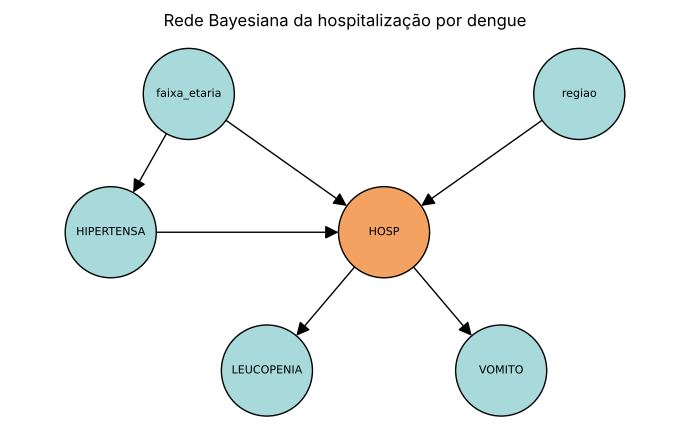

In [ ]:
PAIS = {
    "faixa_etaria": [],
    "regiao":       [],
    "HIPERTENSA":   ["faixa_etaria"],
    "HOSP":         ["regiao", "faixa_etaria", "HIPERTENSA"],
    "LEUCOPENIA":   ["HOSP"],
    "VOMITO":       ["HOSP"],
}
VALORES = {
    "faixa_etaria": ["crianca", "adulto", "idoso"],
    "regiao":       ["centro-oeste", "nordeste", "norte", "sudeste", "sul"],
    "HIPERTENSA":   ["nao", "sim"],
    "HOSP":         ["nao", "sim"],
    "LEUCOPENIA":   ["nao", "sim"],
    "VOMITO":       ["nao", "sim"],
}
print("ordem topológica:", ordem_topologica(PAIS))

G = nx.DiGraph([(p, X) for X, ps in PAIS.items() for p in ps])
pos = {"faixa_etaria": (0, 2), "regiao": (2, 2), "HIPERTENSA": (-0.4, 1),
       "HOSP": (1, 1), "LEUCOPENIA": (0.4, 0), "VOMITO": (1.6, 0)}
cores = ["#f4a261" if n == "HOSP" else "#a8dadc" for n in G.nodes]
fig, ax = plt.subplots(figsize=(7, 4.5))
nx.draw_networkx(G, pos, ax=ax, node_color=cores, node_size=4300, font_size=8,
                 arrowsize=20, edgecolors="k")
ax.set_title("Rede Bayesiana da hospitalização por dengue")
ax.axis("off"); ax.margins(0.15)
fig.tight_layout(); fig.savefig("etapa5_dag.png", dpi=150); plt.show()

## 4. CPTs estimadas do treino

Observação importante: como o treino foi balanceado, as CPTs descrevem o conjunto **balanceado**, e não a população. Em particular, `HOSP` tem 50% de hospitalizações, contra cerca de 8,6% na base real. As razões entre as linhas (o efeito de cada fator) são as mesmas; só o nível de base muda. A seção 1.6 mostra como voltar à prevalência real.

In [ ]:
rede = montar_rede(treino, PAIS, VALORES)
pd.set_option("display.width", 200)
for X in rede["ordem"]:
    print(f"--- P({X} | {', '.join(PAIS[X]) or 'sem pais'})")
    print(tabela_cpt(rede, X).round(4).to_string(index=False), "\n")

--- P(faixa_etaria | sem pais)
 P(faixa_etaria=crianca)  P(faixa_etaria=adulto)  P(faixa_etaria=idoso)
                  0.1685                  0.7026                 0.1289 

--- P(regiao | sem pais)
 P(regiao=centro-oeste)  P(regiao=nordeste)  P(regiao=norte)  P(regiao=sudeste)  P(regiao=sul)
                 0.2739               0.303           0.0811             0.3088         0.0332 

--- P(HIPERTENSA | faixa_etaria)
faixa_etaria  P(HIPERTENSA=nao)  P(HIPERTENSA=sim)
     crianca             0.9941             0.0059
      adulto             0.9308             0.0692
       idoso             0.5638             0.4362 

--- P(HOSP | regiao, faixa_etaria, HIPERTENSA)
      regiao faixa_etaria HIPERTENSA  P(HOSP=nao)  P(HOSP=sim)
centro-oeste      crianca        nao       0.5687       0.4313
centro-oeste      crianca        sim       0.5000       0.5000
centro-oeste       adulto        nao       0.6453       0.3547
centro-oeste       adulto        sim       0.4418       0.5582
centr

## 5. Inferência por enumeração

**Cálculo detalhado.** Consulta $P(\text{HOSP} \mid \text{idoso}, \text{nordeste}, \text{leucopenia} = \text{sim})$. As variáveis ocultas são `HIPERTENSA` e `VOMITO`, então:

$$P(h \mid e) = \alpha \sum_{hip}\sum_{vom} P(\text{idoso})\,P(\text{nordeste})\,P(hip \mid \text{idoso})\,P(h \mid \text{nordeste}, \text{idoso}, hip)\,P(\text{leuc} \mid h)\,P(vom \mid h).$$

Como `VOMITO` não é observado e não tem filhos, a soma $\sum_{vom} P(vom \mid h) = 1$: ele "some" da conta (AIMA, seção 12.6). A tabela abaixo mostra os 8 termos.

In [ ]:
e = {"faixa_etaria": "idoso", "regiao": "nordeste", "LEUCOPENIA": "sim"}
termos = []
for h in VALORES["HOSP"]:
    for hip in VALORES["HIPERTENSA"]:
        for vom in VALORES["VOMITO"]:
            a = {**e, "HOSP": h, "HIPERTENSA": hip, "VOMITO": vom}
            fatores = {X: prob_no(rede, X, a[X], a) for X in rede["ordem"]}
            termos.append({"HOSP": h, "HIPERTENSA": hip, "VOMITO": vom,
                           **{f"P({X})": f for X, f in fatores.items()},
                           "produto": np.prod(list(fatores.values()))})
termos = pd.DataFrame(termos)
print(termos.round(5).to_string(index=False))

soma = termos.groupby("HOSP")["produto"].sum()
print("\nsoma por valor de HOSP (não normalizada):", soma.round(6).to_dict())
print("normalizado (alpha = 1 / soma):          ", (soma / soma.sum()).round(4).to_dict())
print("enumeration_ask:                         ",
      {k: round(v, 4) for k, v in enumeration_ask(rede, "HOSP", e).items()})

HOSP HIPERTENSA VOMITO  P(faixa_etaria)  P(regiao)  P(HIPERTENSA)  P(HOSP)  P(LEUCOPENIA)  P(VOMITO)  produto
 nao        nao    nao          0.12893    0.30295        0.56383  0.29178        0.03713    0.72022  0.00017
 nao        nao    sim          0.12893    0.30295        0.56383  0.29178        0.03713    0.27978  0.00007
 nao        sim    nao          0.12893    0.30295        0.43617  0.17398        0.03713    0.72022  0.00008
 nao        sim    sim          0.12893    0.30295        0.43617  0.17398        0.03713    0.27978  0.00003
 sim        nao    nao          0.12893    0.30295        0.56383  0.70822        0.15126    0.58268  0.00137
 sim        nao    sim          0.12893    0.30295        0.56383  0.70822        0.15126    0.41732  0.00098
 sim        sim    nao          0.12893    0.30295        0.43617  0.82602        0.15126    0.58268  0.00124
 sim        sim    sim          0.12893    0.30295        0.43617  0.82602        0.15126    0.41732  0.00089

soma por 

**Consultas clínicas.** As primeiras são **preditivas/causais** (das causas para a hospitalização); as últimas são **diagnósticas** (do desfecho para os achados e fatores de risco), que a rede responde com a mesma função, aplicando Bayes implicitamente. A última coluna corrige para a prevalência real (só faz sentido nas consultas sobre `HOSP`).

In [ ]:
CONSULTAS = [
    ("HOSP", {}),
    ("HOSP", {"faixa_etaria": "idoso"}),
    ("HOSP", {"faixa_etaria": "idoso", "HIPERTENSA": "sim"}),
    ("HOSP", {"faixa_etaria": "idoso", "LEUCOPENIA": "sim"}),
    ("HOSP", {"regiao": "nordeste", "VOMITO": "sim"}),
    ("HOSP", {"regiao": "sudeste", "faixa_etaria": "adulto", "LEUCOPENIA": "nao", "VOMITO": "nao"}),
    ("HOSP", {"regiao": "nordeste", "faixa_etaria": "crianca", "LEUCOPENIA": "sim", "VOMITO": "sim"}),
    ("LEUCOPENIA", {"HOSP": "sim"}),
    ("LEUCOPENIA", {"HOSP": "nao"}),
    ("HIPERTENSA", {"HOSP": "sim"}),
    ("faixa_etaria", {"HOSP": "sim"}),
]

linhas = []
for X, ev in CONSULTAS:
    d = enumeration_ask(rede, X, ev)
    alvo = "sim" if "sim" in d else "idoso"
    linha = {"consulta": f"P({X}={alvo} | " + (", ".join(f"{k}={v}" for k, v in ev.items()) or "nada") + ")",
             "rede (balanceada)": d[alvo]}
    linha["prevalência real"] = corrigir_prevalencia(d[alvo], PI) if X == "HOSP" else np.nan
    linhas.append(linha)
pd.set_option("display.max_colwidth", 120)
print(pd.DataFrame(linhas).round(4).to_string(index=False))

                                                                       consulta  rede (balanceada)  prevalência real
                                                             P(HOSP=sim | nada)             0.4984            0.0851
                                               P(HOSP=sim | faixa_etaria=idoso)             0.6695            0.1594
                               P(HOSP=sim | faixa_etaria=idoso, HIPERTENSA=sim)             0.7470            0.2166
                               P(HOSP=sim | faixa_etaria=idoso, LEUCOPENIA=sim)             0.8919            0.4359
                                      P(HOSP=sim | regiao=nordeste, VOMITO=sim)             0.7460            0.2157
  P(HOSP=sim | regiao=sudeste, faixa_etaria=adulto, LEUCOPENIA=nao, VOMITO=nao)             0.2520            0.0306
P(HOSP=sim | regiao=nordeste, faixa_etaria=crianca, LEUCOPENIA=sim, VOMITO=sim)             0.9428            0.6067
                                                   P(LEUCOPENIA=

## 6. Comparação com o pgmpy (VariableElimination)

A mesma rede (mesmas CPTs) é montada no pgmpy, e as consultas da seção 5 são repetidas com **eliminação de variáveis**. Também comparamos 300 consultas sorteadas, com evidência parcial (de 0 a 5 nós observados) e qualquer nó como alvo. Os resultados devem ser idênticos até o erro de arredondamento.

In [ ]:
modelo_pg = para_pgmpy(rede)
ve = VariableElimination(modelo_pg)


def consulta_pgmpy(X, ev):
    q = ve.query(variables=[X], evidence=ev or None, show_progress=False)
    return dict(zip(q.state_names[X], q.values))


linhas = []
for X, ev in CONSULTAS:
    a, b = enumeration_ask(rede, X, ev), consulta_pgmpy(X, ev)
    alvo = "sim" if "sim" in a else "idoso"
    linhas.append({"consulta": f"P({X}={alvo} | {ev})", "enumeração": a[alvo], "pgmpy": b[alvo]})
print(pd.DataFrame(linhas).round(6).to_string(index=False))

rng = np.random.default_rng(SEED)
nos, maior = rede["ordem"], 0.0
for _ in range(300):
    X = nos[rng.integers(len(nos))]
    outros = [n for n in nos if n != X]
    obs = rng.choice(outros, size=rng.integers(0, len(outros) + 1), replace=False)
    ev = {n: VALORES[n][rng.integers(len(VALORES[n]))] for n in obs}
    a, b = enumeration_ask(rede, X, ev), consulta_pgmpy(X, ev)
    maior = max(maior, max(abs(a[v] - b[v]) for v in VALORES[X]))
print(f"\n300 consultas sorteadas: maior diferença enumeração x pgmpy = {maior:.2e}")

                                                                                             consulta  enumeração    pgmpy
                                                                                     P(HOSP=sim | {})    0.498411 0.498411
                                                              P(HOSP=sim | {'faixa_etaria': 'idoso'})    0.669488 0.669488
                                         P(HOSP=sim | {'faixa_etaria': 'idoso', 'HIPERTENSA': 'sim'})    0.746965 0.746965
                                         P(HOSP=sim | {'faixa_etaria': 'idoso', 'LEUCOPENIA': 'sim'})    0.891912 0.891912
                                                P(HOSP=sim | {'regiao': 'nordeste', 'VOMITO': 'sim'})    0.746030 0.746030
  P(HOSP=sim | {'regiao': 'sudeste', 'faixa_etaria': 'adulto', 'LEUCOPENIA': 'nao', 'VOMITO': 'nao'})    0.251973 0.251973
P(HOSP=sim | {'regiao': 'nordeste', 'faixa_etaria': 'crianca', 'LEUCOPENIA': 'sim', 'VOMITO': 'sim'})    0.942767 0.942767
                


300 consultas sorteadas: maior diferença enumeração x pgmpy = 2.22e-16


## 7. d-separação e o caso do colisor

Verificamos independências condicionais pelo grafo (função própria da seção 1.4, conferida com `is_dconnected` do pgmpy):

1. **LEUCOPENIA ⟂ VOMITO | HOSP** — `HOSP` é causa comum dos dois (caso 1 do Bratko, fig. 16.6). Observá-la bloqueia o caminho.
2. **HIPERTENSA ⟂ LEUCOPENIA | HOSP** — `HOSP` está no meio de uma cadeia (caso 2), e os dois caminhos entre elas passam por ela.
3. **regiao ⟂ faixa_etaria** sem evidência, mas **dependentes dado HOSP** ou dado um descendente de `HOSP` (como `LEUCOPENIA`) — `HOSP` é colisor (caso 3).

In [ ]:
TESTES = [
    ("LEUCOPENIA", "VOMITO", []),
    ("LEUCOPENIA", "VOMITO", ["HOSP"]),
    ("HIPERTENSA", "LEUCOPENIA", []),
    ("HIPERTENSA", "LEUCOPENIA", ["HOSP"]),
    ("regiao", "faixa_etaria", []),
    ("regiao", "faixa_etaria", ["HOSP"]),
    ("regiao", "faixa_etaria", ["LEUCOPENIA"]),
    ("regiao", "HIPERTENSA", ["HOSP"]),
]
linhas = []
for X, Y, Z in TESTES:
    nosso = d_separados(PAIS, X, Y, Z)
    pg = not modelo_pg.is_dconnected(X, Y, observed=Z)
    linhas.append({"X": X, "Y": Y, "dado": ", ".join(Z) or "(nada)",
                   "d-separados (nosso)": nosso, "d-separados (pgmpy)": pg})
print(pd.DataFrame(linhas).to_string(index=False))

         X            Y       dado  d-separados (nosso)  d-separados (pgmpy)
LEUCOPENIA       VOMITO     (nada)                False                False
LEUCOPENIA       VOMITO       HOSP                 True                 True
HIPERTENSA   LEUCOPENIA     (nada)                False                False
HIPERTENSA   LEUCOPENIA       HOSP                 True                 True
    regiao faixa_etaria     (nada)                 True                 True
    regiao faixa_etaria       HOSP                False                False
    regiao faixa_etaria LEUCOPENIA                False                False
    regiao   HIPERTENSA       HOSP                False                False


**Confirmação numérica pelas CPTs.** Se X ⟂ Y | Z, então $P(X \mid Y, Z)$ não muda quando Y muda. A conta é feita por enumeração na própria rede.

In [ ]:
def p(X, xv, **ev):
    return enumeration_ask(rede, X, ev)[xv]

print("1) LEUCOPENIA x VOMITO dado HOSP=sim (devem ser iguais):")
print(f"   P(leuc=sim | hosp=sim, vom=sim) = {p('LEUCOPENIA', 'sim', HOSP='sim', VOMITO='sim'):.4f}")
print(f"   P(leuc=sim | hosp=sim, vom=nao) = {p('LEUCOPENIA', 'sim', HOSP='sim', VOMITO='nao'):.4f}")
print("   sem observar HOSP (devem ser diferentes):")
print(f"   P(leuc=sim | vom=sim) = {p('LEUCOPENIA', 'sim', VOMITO='sim'):.4f}")
print(f"   P(leuc=sim | vom=nao) = {p('LEUCOPENIA', 'sim', VOMITO='nao'):.4f}")

print("\n2) HIPERTENSA x LEUCOPENIA dado HOSP=sim (devem ser iguais):")
print(f"   P(hip=sim | hosp=sim, leuc=sim) = {p('HIPERTENSA', 'sim', HOSP='sim', LEUCOPENIA='sim'):.4f}")
print(f"   P(hip=sim | hosp=sim, leuc=nao) = {p('HIPERTENSA', 'sim', HOSP='sim', LEUCOPENIA='nao'):.4f}")

print("\n3) Colisor regiao -> HOSP <- faixa_etaria")
print(f"   P(nordeste)                       = {p('regiao', 'nordeste'):.4f}")
print(f"   P(nordeste | idoso)               = {p('regiao', 'nordeste', faixa_etaria='idoso'):.4f}   (igual: independentes)")
print(f"   P(nordeste | hosp=sim)            = {p('regiao', 'nordeste', HOSP='sim'):.4f}")
print(f"   P(nordeste | hosp=sim, idoso)     = {p('regiao', 'nordeste', HOSP='sim', faixa_etaria='idoso'):.4f}   (diferente: observar o colisor abre o caminho)")
print(f"   P(nordeste | leuc=sim)            = {p('regiao', 'nordeste', LEUCOPENIA='sim'):.4f}")
print(f"   P(nordeste | leuc=sim, idoso)     = {p('regiao', 'nordeste', LEUCOPENIA='sim', faixa_etaria='idoso'):.4f}   (descendente do colisor também abre)")

1) LEUCOPENIA x VOMITO dado HOSP=sim (devem ser iguais):
   P(leuc=sim | hosp=sim, vom=sim) = 0.1513
   P(leuc=sim | hosp=sim, vom=nao) = 0.1513
   sem observar HOSP (devem ser diferentes):
   P(leuc=sim | vom=sim) = 0.1053
   P(leuc=sim | vom=nao) = 0.0880

2) HIPERTENSA x LEUCOPENIA dado HOSP=sim (devem ser iguais):
   P(hip=sim | hosp=sim, leuc=sim) = 0.1419
   P(hip=sim | hosp=sim, leuc=nao) = 0.1419

3) Colisor regiao -> HOSP <- faixa_etaria
   P(nordeste)                       = 0.3030
   P(nordeste | idoso)               = 0.3030   (igual: independentes)
   P(nordeste | hosp=sim)            = 0.4031
   P(nordeste | hosp=sim, idoso)     = 0.3437   (diferente: observar o colisor abre o caminho)
   P(nordeste | leuc=sim)            = 0.3636
   P(nordeste | leuc=sim, idoso)     = 0.3304   (descendente do colisor também abre)


**Confirmação nos dados.** O modelo *impõe* as independências; os dados mostram até que ponto elas valem de verdade. Medimos a **informação mútua condicional** $I(X;Y \mid Z)$ em bits (0 = independência exata) e comparamos com a dependência sem condicionar.

Para o colisor, usamos também a base **natural** (todos os casos válidos, sem balancear). Isso importa: o *undersampling* escolheu os pacientes **pelo valor de `HOSP`**, que é exatamente o colisor. Selecionar a amostra pelo colisor equivale a observá-lo, então o balanceamento por si só já cria dependência entre região e idade (viés de seleção).

In [ ]:
def info_mutua(df, X, Y, Z=()):
    """I(X; Y | Z) em bits, estimada pelas frequências do DataFrame."""
    grupos = df.groupby(list(Z)) if Z else [(None, df)]
    total = 0.0
    for _, g in grupos:
        j = pd.crosstab(g[X], g[Y], normalize=True).to_numpy()
        px, py = j.sum(1, keepdims=True), j.sum(0, keepdims=True)
        with np.errstate(divide="ignore", invalid="ignore"):
            total += len(g) / len(df) * np.nansum(j * np.log2(j / (px * py)))
    return total

linhas = [
    ("LEUCOPENIA", "VOMITO", (), "treino"), ("LEUCOPENIA", "VOMITO", ("HOSP",), "treino"),
    ("HIPERTENSA", "LEUCOPENIA", (), "treino"), ("HIPERTENSA", "LEUCOPENIA", ("HOSP",), "treino"),
    ("regiao", "faixa_etaria", (), "base natural"), ("regiao", "faixa_etaria", ("HOSP",), "base natural"),
    ("regiao", "faixa_etaria", (), "treino (balanceado)"),
    ("HIPERTENSA", "faixa_etaria", (), "treino"), ("HIPERTENSA", "faixa_etaria", ("HOSP",), "treino"),
]
res = []
for X, Y, Z, base in linhas:
    df_ = nat if base == "base natural" else treino
    res.append({"X": X, "Y": Y, "dado": ", ".join(Z) or "(nada)", "base": base,
                "I(X;Y|Z) bits": info_mutua(df_, X, Y, Z)})
print(pd.DataFrame(res).round(5).to_string(index=False))
print("\n(referência: I(regiao; HOSP) no treino =", round(info_mutua(treino, "regiao", "HOSP"), 5), "bits)")

         X            Y   dado                base  I(X;Y|Z) bits
LEUCOPENIA       VOMITO (nada)              treino        0.00285
LEUCOPENIA       VOMITO   HOSP              treino        0.00091
HIPERTENSA   LEUCOPENIA (nada)              treino        0.00174
HIPERTENSA   LEUCOPENIA   HOSP              treino        0.00058
    regiao faixa_etaria (nada)        base natural        0.00605
    regiao faixa_etaria   HOSP        base natural        0.00672
    regiao faixa_etaria (nada) treino (balanceado)        0.01026
HIPERTENSA faixa_etaria (nada)              treino        0.09618
HIPERTENSA faixa_etaria   HOSP              treino        0.09159

(referência: I(regiao; HOSP) no treino = 0.04479 bits)


## 8. Economia de parâmetros

Comparamos a rede final com a distribuição conjunta completa das mesmas 6 variáveis e com duas estruturas alternativas, todas com os mesmos nós:

* **estrutura Naive Bayes**: `HOSP` como pai de todos os outros nós (a hipótese da Etapa 4);
* **HOSP com todos os pais**: os 5 atributos apontando para `HOSP` (uma tabela completa de $P(\text{HOSP} \mid \text{atributos})$).

Para cada uma reportamos o número de parâmetros e a log-verossimilhança média no teste, $\frac{1}{N}\sum \log P(\text{paciente})$ (maior é melhor). Ela mede quão bem a rede descreve os pacientes inteiros, não só a hospitalização.

In [ ]:
por_no, total, conjunta = parametros(rede)
print("parâmetros por nó:")
for X, n in por_no.items():
    print(f"  {X:13s} pais={PAIS[X]!s:42s} -> {n}")
print(f"\nrede: {total} | conjunta completa: {conjunta} | economia: {conjunta - total} números "
      f"({100 * (1 - total / conjunta):.1f}% a menos)")

ESTRUTURAS = {
    "rede final (causal)": PAIS,
    "estrutura Naive Bayes": {"HOSP": [], **{a: ["HOSP"] for a in ["regiao", "faixa_etaria", "HIPERTENSA", "LEUCOPENIA", "VOMITO"]}},
    "HOSP com todos os pais": {"HOSP": ["regiao", "faixa_etaria", "HIPERTENSA", "LEUCOPENIA", "VOMITO"],
                               **{a: [] for a in ["regiao", "faixa_etaria", "HIPERTENSA", "LEUCOPENIA", "VOMITO"]}},
}
linhas = []
for nome, ps in ESTRUTURAS.items():
    r = montar_rede(treino, ps, VALORES)
    # log-verossimilhança média no teste (cada combinação diferente é calculada uma vez)
    cols = list(VALORES)
    cont = teste.groupby(cols).size()
    ll = sum(n * np.log(prob_conjunta(r, dict(zip(cols, k)))) for k, n in cont.items()) / len(teste)
    m = metricas(yte, prob_hosp_rede(r, teste))
    linhas.append({"estrutura": nome, "parâmetros": parametros(r)[1], "logL médio teste": ll,
                   "acurácia teste": m["acuracia"], "AUC teste": m["auc"], "log-loss teste": m["log_loss"]})
linhas.append({"estrutura": "conjunta completa", "parâmetros": conjunta, "logL médio teste": np.nan,
               "acurácia teste": np.nan, "AUC teste": np.nan, "log-loss teste": np.nan})
print()
print(pd.DataFrame(linhas).round(4).to_string(index=False))

parâmetros por nó:
  faixa_etaria  pais=[]                                         -> 2
  regiao        pais=[]                                         -> 4
  HIPERTENSA    pais=['faixa_etaria']                           -> 3
  HOSP          pais=['regiao', 'faixa_etaria', 'HIPERTENSA']   -> 30
  LEUCOPENIA    pais=['HOSP']                                   -> 2
  VOMITO        pais=['HOSP']                                   -> 2

rede: 43 | conjunta completa: 239 | economia: 196 números (82.0% a menos)

             estrutura  parâmetros  logL médio teste  acurácia teste  AUC teste  log-loss teste
   rede final (causal)          43           -4.0566          0.6567     0.7147          0.6174
 estrutura Naive Bayes          19           -4.1216          0.6563     0.7132          0.6182
HOSP com todos os pais         129           -4.1273          0.6560     0.7145          0.6173
     conjunta completa         239               NaN             NaN        NaN             NaN


## 9. A rede como classificador e comparação com as etapas anteriores

Mesmo protocolo das Etapas 1 e 4: acurácia de treino e de teste com a rede estimada no treino, e validação 5-fold no conjunto balanceado inteiro (treino + teste), com limiar 0,5. Os valores de ID3, Naive Bayes e NB + EM são os obtidos nas Etapas 1 e 4 (mesmo treino/teste e mesmos folds). Se o arquivo `etapa4_probabilidades_teste.csv` estiver em `/content`, as métricas de teste da Etapa 4 são recalculadas a partir dele.

In [ ]:
p_tr = prob_hosp_rede(rede, treino)
p_te = prob_hosp_rede(rede, teste)
dados_cv = pd.concat([treino, teste]).reset_index(drop=True)
cv = cv_rede(dados_cv, PAIS, VALORES)

m_te = metricas(yte, p_te)
linhas = [{"modelo": "Rede Bayesiana (Etapa 5)", "treino": metricas(ytr, p_tr)["acuracia"],
           "teste": m_te["acuracia"], "5-fold (media)": np.mean([r["acuracia"] for r in cv]),
           "AUC teste": m_te["auc"], "log-loss teste": m_te["log_loss"]}]

# Referências: valores impressos nos notebooks das Etapas 1 e 4
REF = [
    {"modelo": "ID3 sem poda (Etapa 1)", "treino": 0.6670, "teste": 0.6632, "5-fold (media)": 0.6627, "AUC teste": np.nan, "log-loss teste": np.nan},
    {"modelo": "Naive Bayes (Etapa 4)",  "treino": 0.6623, "teste": 0.6689, "5-fold (media)": 0.6636, "AUC teste": 0.7251, "log-loss teste": 0.6105},
    {"modelo": "NB + EM K=3 (Etapa 4)",  "treino": 0.6660, "teste": 0.6644, "5-fold (media)": 0.6657, "AUC teste": 0.7269, "log-loss teste": 0.6092},
]
if os.path.exists("etapa4_probabilidades_teste.csv"):
    e4 = pd.read_csv("etapa4_probabilidades_teste.csv")
    assert (e4["alvo"].to_numpy() == yte).all(), "o CSV da Etapa 4 não corresponde a este teste"
    for ref, col in [(REF[1], "p_nb"), (REF[2], "p_nb_em_k3")]:
        mm = metricas(yte, e4[col].to_numpy())
        ref.update({"teste": mm["acuracia"], "AUC teste": mm["auc"], "log-loss teste": mm["log_loss"]})
    print("métricas da Etapa 4 recalculadas a partir de etapa4_probabilidades_teste.csv\n")

print(pd.DataFrame(linhas + REF).round(4).to_string(index=False))
print("\n5-fold rede:", [round(r["acuracia"], 4) for r in cv])

métricas da Etapa 4 recalculadas a partir de etapa4_probabilidades_teste.csv

                  modelo  treino  teste  5-fold (media)  AUC teste  log-loss teste
Rede Bayesiana (Etapa 5)  0.6599 0.6567          0.6571     0.7147          0.6174
  ID3 sem poda (Etapa 1)  0.6670 0.6632          0.6627        NaN             NaN
   Naive Bayes (Etapa 4)  0.6623 0.6689          0.6636     0.7251          0.6105
   NB + EM K=3 (Etapa 4)  0.6660 0.6644          0.6657     0.7269          0.6092

5-fold rede: [0.6529, 0.661, 0.6584, 0.6559, 0.6574]


**Distribuição das probabilidades no teste.** Este é o insumo da Etapa 6: o sistema fuzzy vai receber essas probabilidades. Mostramos o histograma por desfecho real e a mesma probabilidade corrigida para a prevalência real.

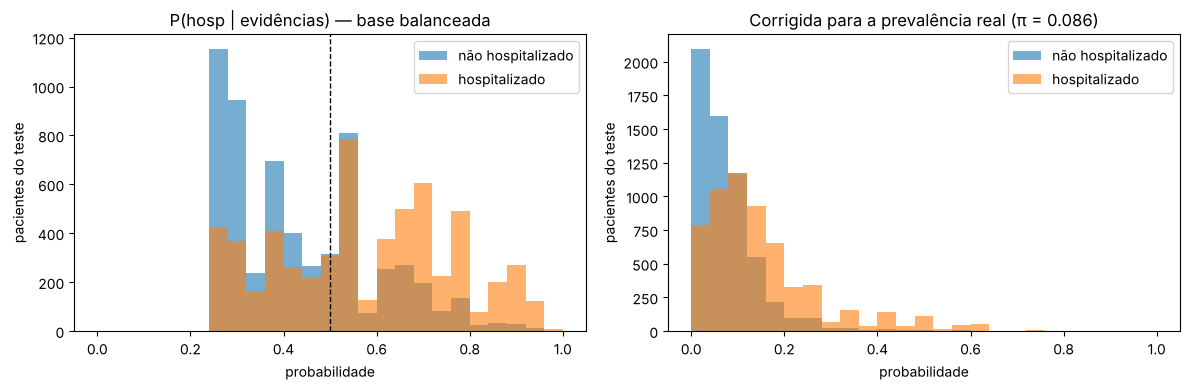

                  pacientes  taxa_real_hosp
faixa de P(hosp)                           
(-0.001, 0.3]          2887           0.273
(0.3, 0.45]            2190           0.384
(0.45, 0.55]           2680           0.487
(0.55, 0.7]            2365           0.666
(0.7, 1.0]             1754           0.814


In [ ]:
p_real = corrigir_prevalencia(p_te, PI)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
bins = np.linspace(0, 1, 26)
for y, nome in [(0, "não hospitalizado"), (1, "hospitalizado")]:
    ax[0].hist(p_te[yte == y], bins=bins, alpha=0.6, label=nome)
    ax[1].hist(p_real[yte == y], bins=bins, alpha=0.6, label=nome)
ax[0].axvline(0.5, color="k", ls="--", lw=1)
ax[0].set_title("P(hosp | evidências) — base balanceada"); ax[0].set_xlabel("probabilidade"); ax[0].legend()
ax[1].set_title(f"Corrigida para a prevalência real (π = {PI:.3f})"); ax[1].set_xlabel("probabilidade"); ax[1].legend()
for a in ax:
    a.set_ylabel("pacientes do teste")
fig.tight_layout(); fig.savefig("etapa5_probabilidades.png", dpi=150); plt.show()

faixas = pd.cut(p_te, [0, 0.3, 0.45, 0.55, 0.7, 1.0], include_lowest=True)
print(pd.DataFrame({"faixa de P(hosp)": faixas, "hosp": yte})
      .groupby("faixa de P(hosp)", observed=True)["hosp"].agg(pacientes="size", taxa_real_hosp="mean")
      .round(3).to_string())

## 10. Salvar as probabilidades (entrada da Etapa 6)

`etapa5_probabilidades_teste.csv` traz, para cada paciente do teste, os atributos, o alvo, `p_rede` (base balanceada, comparável às etapas anteriores e ao limiar 0,5) e `p_rede_real` (corrigida para a prevalência real).

In [ ]:
saida = teste_bruto[ATRIBUTOS + ["alvo"]].copy()
saida["p_rede"] = p_te
saida["p_rede_real"] = p_real
saida.to_csv("etapa5_probabilidades_teste.csv", index=False)
print("salvo: etapa5_probabilidades_teste.csv", saida.shape)
print(saida.head().round(4).to_string(index=False))

salvo: etapa5_probabilidades_teste.csv (11876, 9)
      regiao LEUCOPENIA faixa_etaria VOMITO CEFALEIA HIPERTENSA  alvo  p_rede  p_rede_real
centro-oeste        2.0       adulto    1.0      1.0        2.0     0  0.4195       0.0634
centro-oeste        2.0       adulto    2.0      1.0        2.0     0  0.2816       0.0354
centro-oeste        2.0       adulto    2.0      1.0        2.0     1  0.2816       0.0354
     sudeste        2.0       adulto    2.0      1.0        2.0     1  0.2432       0.0292
    nordeste        1.0      crianca    2.0      2.0        2.0     1  0.8994       0.4556
